# A. TRAINING ENVIRONMENTS

## Peg and Hole
   We developed our code within the Factory simulation framework. For the
   `PEG AND HOLE` assemblies, 
    1. we first trained a `REACH` policy, where the robot learned to move its 
       end-effector to a randomised pose within a large workspace.  
    2. We then fine-tuned `REACH` to solve the `PICK` task by including all 
       peg assets in the scene and redefining success as lifting the pegs.
    3. Similarly, we fine-tuned `REACH` to solve the `PLACE` task by:
       a. initialising the pegs within the robot grippers
       b. including all hole assets in the scene
       c. and redefining success as bringing the pegs to their corresponding 
          holes 

   Empirically,
   1. For the `PICK` and `PLACE` tasks, training in free space and fine-tuning 
      on contact was more efficient than training from scratch ... 
   2. HOWEVER, we trained an `INSERT` policy from scratch

----
# Gears and Gearshafts
   ... did not train policies to solve the `PICK` or `PLACE` tasks, ...
   we solve those tasks in the real world by executing the corresponding 
   `PEG and HOLE` policies, demonstrating GENERALIZATION. However, we again
   trained an `INSERT` policy from scratch ... 

---
# Connectors and Receptacles
   ... we did not train policies for any phase. ... we later show that we solved
   those tasks in the real world via POLICY TRANSFER. 

---
   In summary, for the PEG AND HOLE assemblies, we trained PICK, PLACE, and
   INSERT policies, and for the GEARS AND GEARSHAFTS ASSEMBLIES, we trained
   another `INSERT` policy ... 

---











-- ... they first trained a `REACH` policy to mvoe the end-effector to random
   poses in a large empty workspace ... they then fine-tuned copies of it for 
   `PICK` (with pegs added and success meaning the peg is lifted) ... and 
   for `PLACE` (with the peg starting in the gripper and success ) ... The paper
   says this was mroe efficient than training Pick and place from scratch, but 
   insert was traing from scratch ... 

-- ... you still need a controller, because common policies do not output
   motor torque or current at the kilo-hertz rate a motor loop needs. ACT on
   ALOHA outputs a chunk of target robot-joint positions at about 50 Hz
   , and many VLAs such as OpenVLA output a small end-effector pose change
   at only a few Hz. A TCP target needs an IK `&&` impedance controller 
   to turn it into joint commands, while a joint target skips that step ... 
   
   Even joint targets go to a PID loop inside each motor driver that runs at
   around 1 kHz, so the hand-written controller gets thinner but never goes 
   away ... 

-- .... impedance controller regulates the dynamic relationship between forces
   and motion (like a virtual spring-mass-damper) during physical contact ... 

-- ALOHA (A Low-Cost Open-Source Hardware System for Bimanual Teleoperation)
   is an open-source two-arm teleoperation hardware platform created alongside 
   the ACT imitation learning policy to teach robots fine-grained 
   manipulation tasks from small sets of human demonstration ... 

-- ... in peg-in-hole assembly, CLEARANCE is the physical gap between the hole's
   radius or diameter and the peg's radius or diameter ... when the hole is 
   larger than the peg (a clearance fit)... It determines how much room the 
   pg ...

   - TIGHT TOLERANCES AMPLIFY ERROR: Clearances in peg-in-hole tasks are often
     sub-millimeter ... or down to tens of micrometers ... 
   - JAMMING AND WEDGING: Even small position or angle errors can cause ... 

---

# B. FORMULATION

-- Formulating a task as an MDP (`Markov Decision Process`) just means you
   name the states and actions and reward, and you assume the next state
   depends only on the current state and action. 
      Nobody has to know T or write it down, and my ... 
   Think of a vending machine ... hidden wiring isT and you only learn which
   button gives a drink by pressing buttons and seeing what comes out. 
   PPO treats Isaac Gym as that machine, so it only ever samples from T and
   never a table, which is why a state like `BLACK HOLE` never shows up . 

-- ... `r (0, 0.1 and 1)`

> ... can i for now just presume that how PPO works is just it outputs a 
> distribution, before it randomly samples over such distribution to get an
> exact target output

   The sampling step is random and not deterministic. In PPO, the network 
   outputs a mean and a spread, and then one line of code draws a random action
   from that Gaussian (Normal) distribution... This randomness is what lets the
   agent try slightly different actions during training. At deployment many people skip the sampling and just send the mean, which makes the policy
   deterministic... 


---
> what happens when you use ACT models and train it with PPO then? would we 
> need some kind of encoder block to make ACT output a distributionthen instead?

   ... don't need a new encoder. Usuaually you just add a spread. 

   MINIMUM CHANGE
   - Treat ACT's output chunk as the mean of a Gaussian
   - Add one learnable log-std value per action dimension. This is a small set
     of free parameters and not a network
   - Now every chunk has a probability, so PPO's update can work...

   < I kind of understand this but I don't >

   WHAT ELSE BREAKS
   - NO CRITIC: PPO needs a value estimate. You add a value head or a separate
     small critic network
   - CHUNKS CHANGE THE TIME STEP: one PPO "action" become a whole chunk of
     `k` steps. The log-prob covers `k x action-dimension numbers`. The MDP step
     becomes one chunk instead of one control tick??
   - TEMPORAL ENSEMBLING: ACT blends overlapping chunks at run time. The action
     actually sent is then not the one you sampled, so its probability is wrong
     . You turn ensembling off during RL ??
   - COST: PPO on a large transformer takes a lot of samples. It can also wreck
     what the policy learned from demos ... 

   WHAT PEOPLE DO INSTEAD
   - RESIDUAL RL: freeze ACT and train a small PPO policy that adds a correction
     on top of ACT's output. Only the small policy needs the Gaussian and the critic. This is the common route for precise insertion.
   - For diffusion policy there is DPPO. It treats each denoising step as an
     action with a known Gaussian. That gives PPO the pobabilities it needs 
     without a separate head ... 
    



   the critic doesn't produce rewards; the environment's reward function does
   that. What it does is the ... Since you know the RL loop, policies as neural
   nets and training with a MSE loss ... with discounted return. 

   ... the environment's reward function does that ... You said you know the 
   RL loop ... discounted return (adding up future rewards), then covers what
   the critic predicts, how it's trained, and how PPO uses that prediction to
   update the policy. I you want your ... 

THE CHAIN
1. WHAT ARE WE MAXIMISING? One step's reward is short-sighted, because an 
   action can pay off much later. That gives the `return` G_t the sum of
   future rewards. Then `discounting` with `\gamma` makes that sum finite and
   favours sooner rewards. 

2. THE RETURN IS RANDOM. The policy and the environment are both stochastic 
   , so the same state leads to different returns. The `value` $V(s)$
   is the `expected` return from $s$. That's what `V_phi(s) = v` means ... 

3. WE CAN'T COMPUTE THAT EXPECTATIION, SO WE LEARN IT. The critic `V_phi(s) = v`
   is a neural network trained by ordinary MSE regression toward returns we
   actually observed. This is where your question gets its full answer ...

4. WHY BOTHER? A raw return can't tell good actions from good situations. 
   Subtracting `V(s)` gives the `advanbtage`: was this action BETTER THAN 
   EXPECTED? This is the critic's real job. 

5. ACTOR SIDE. The policymakes actions with positive advantage more likely. 
   `PPO's clipped objective` is the safe way to do that? 






-- ... in math notation, $\pi_{\theta} ( ... )$ isn't representing the code 
   function that generates an action--it is representing the PROBABILITY
   DISTRIBUTION over all possible actions. 

   * THE DISTRIBUTION'S QUESTION: A probability distribution always takes a 
     POTENTIAL OUTCOME inside the parentheses and returns a number between
     0 and 1 (its probability)... So $\pi_{\theta} (a | o)$ is answering:
        "What is the probability of taking action a, given that we currently
        see observation o?"



-- It means that PPO changes the actor's weights $\theta$ so that 
   $\pi_{\theta}$ gives a higher probability to an action that turned out 
   better than expected. For a Gaussian policy this mostly mvoes the mean 
   toward the sampled action when A > 0 and get away from it when A < ->

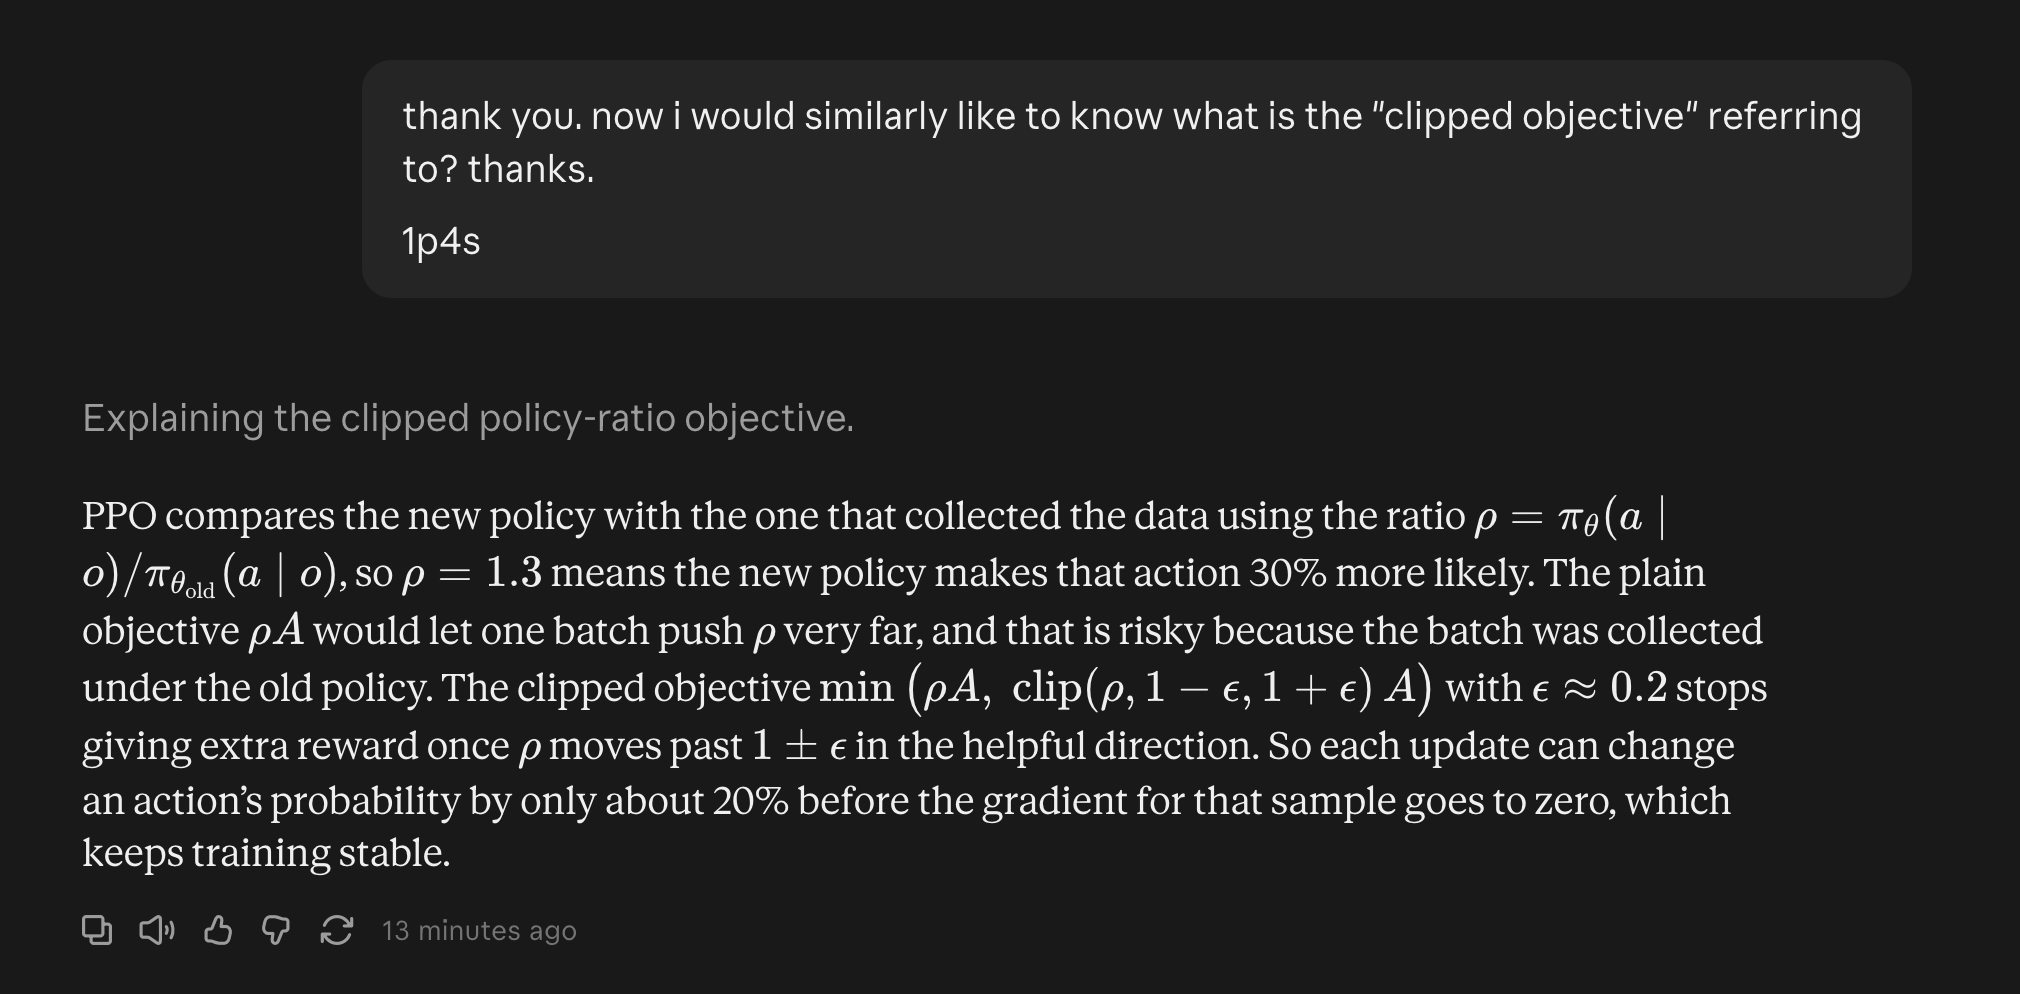

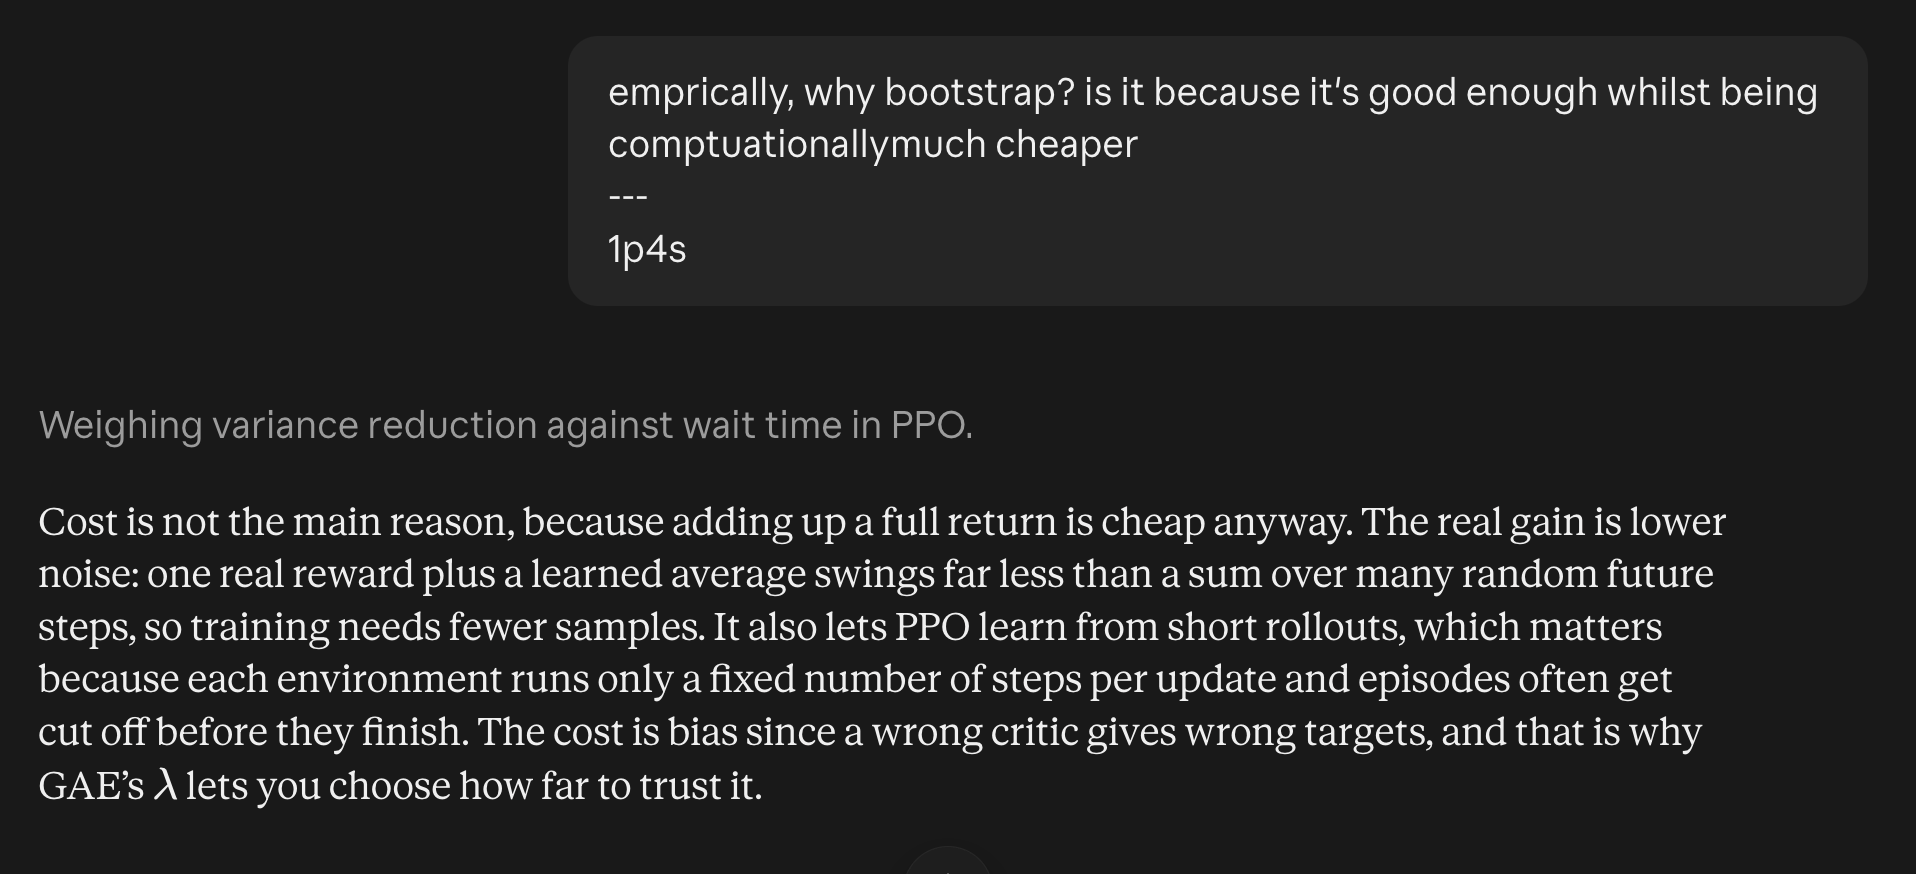

https://www.google.com/search?q=bootstrapped+PPO%2C+what+does+TD+stand+for&oq=bootstrapped+PPO%2C+what+does+TD+stand+for&gs_lcrp=EgZjaHJvbWUyBggAEEUYOTIGCAEQLhhA0gEINjkzMGowajmoAgCwAgE&sourceid=chrome&ie=UTF-8&mstk=AUtExfCHXnhezxuB3cB-ck87-UnMOo9gAxpZxTFs37EUEvdQWbbXs0mngqIUOiA_Lu0pK6A4He-YGoiZZ8RqxYlDqXu0HYnFrCklmveKAYkSWIfgSEQSZsUqMr825PGcWzJHW1JODx-Met-2URi5pFuMjMZpslDO2yB0i94&csuir=1&aioh=3&mtid=xvABa4rbAqDYhbIPg7ThwQQ&udm=50#aof=1

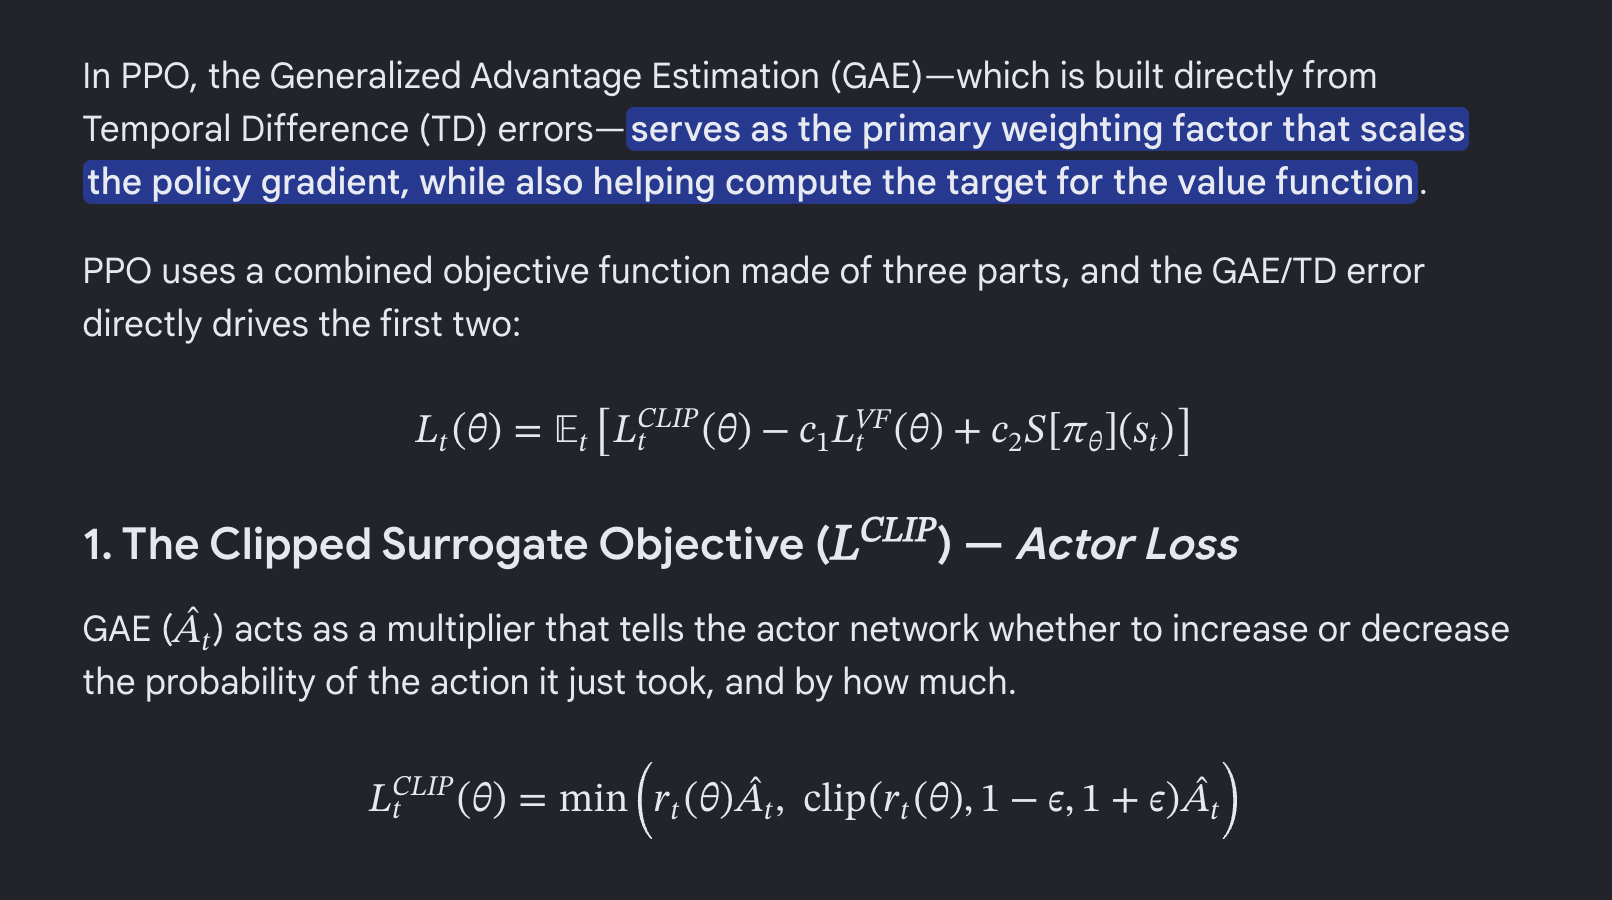

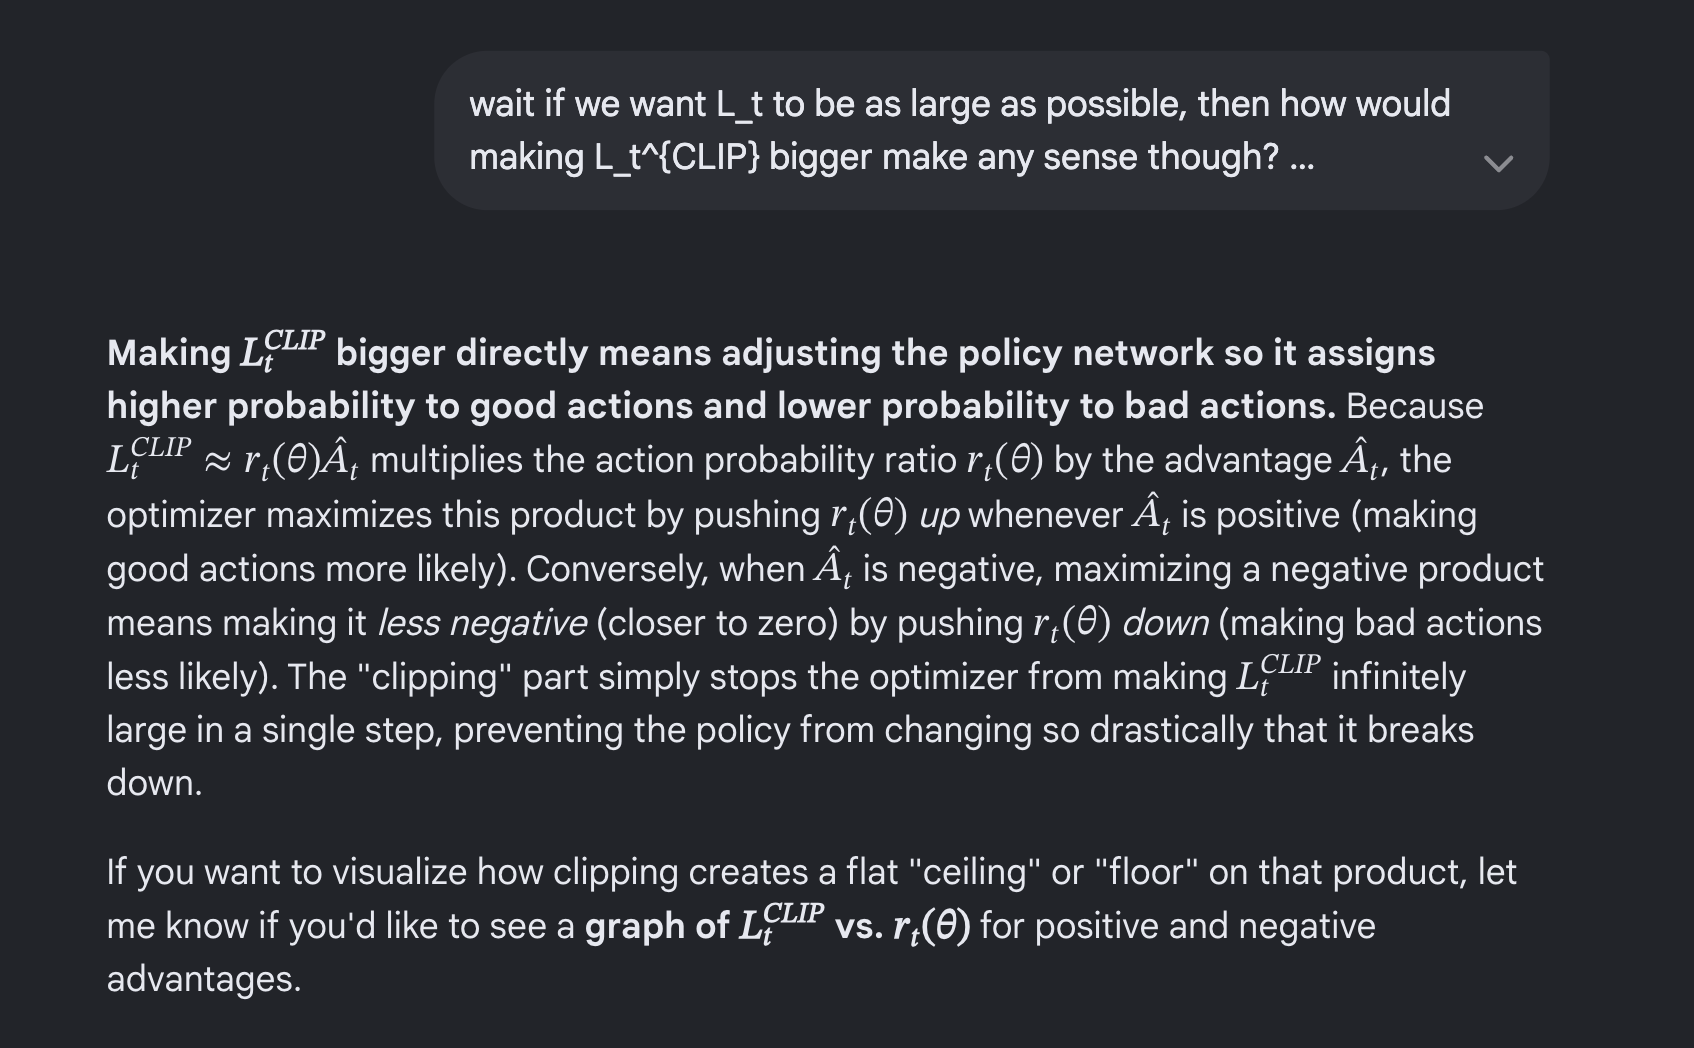